# 03 台灣人的「幸福配方」：全體平均權重與 18 年趨勢

**問題**：對一般台灣上班族來說，工作滿意度與家庭生活滿意度，哪一個和幸福的關係比較大？這個比例 18 年來有沒有變？

**方法選擇與理由**
- **領域滿意度（bottom-up）模型**：把整體幸福視為各生活領域滿意度的組合，是福祉經濟學的標準作法（van Praag, Frijters & Ferrer-i-Carbonell, 2003）。
- **把 1–4 / 1–7 分的量表當成連續變數做 OLS**：Ferrer-i-Carbonell & Frijters (2004) 比較 OLS 與 ordered probit，發現兩者對「哪些因素重要、相對大小」的結論幾乎相同；OLS 的係數可直接解讀成「幾分」，對說故事更清楚。notebook 09 用 ordered logit 做穩健性檢查。
- **控制自評健康**：健康是幸福最強的決定因素之一（Dolan, Peasgood & White, 2008），不控制會讓工作與家庭的效果被高估。
- **標準誤以「人」為群聚**：同一人出現在多個波次，觀測值不獨立。
- **相對重要性用 Shapley 分解**：迴歸係數會因預測變數彼此相關而難以比較；Shapley（又稱 dominance analysis 的一般優勢權重，Budescu, 1993; Grömping, 2007）把 R² 公平分給每個變數，加總 = 總 R²。

In [1]:
import itertools
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
long = pd.read_csv(DERIVED / "long_2007_2024.csv", low_memory=False)
emp = main[(main.employed == 1)].dropna(subset=["swb", "jobsat", "famsat", "econsat", "health", "age", "female"]).copy()
print("分析樣本（2020–2024 有工作者）：", len(emp), "筆，", emp.pid.nunique(), "人")


def fit(formula, d):
    return smf.ols(formula, d).fit(cov_type="cluster", cov_kwds={"groups": d.loc[smf.ols(formula, d).fit().model.data.row_labels, "pid"]})

分析樣本（2020–2024 有工作者）： 13079 筆， 5331 人


## 1. 主模型：每提高一級滿意度，幸福分數多幾分？

In [2]:
F = "swb ~ jobsat + famsat + econsat + health + age + I(age**2) + female + web + C(year)"
m1 = fit(F, emp)
coef_table(m1, ["jobsat", "famsat", "econsat", "health", "age", "female", "web"])

,coef,se,p,ci_low,ci_high
jobsat,5.8443,0.2800,0.0000,5.2955,6.3931
famsat,8.2845,0.2796,0.0000,7.7364,8.8325
econsat,4.4889,0.2318,0.0000,4.0345,4.9433
health,5.1011,0.1888,0.0000,4.7311,5.4712
age,-0.0812,0.0999,0.4163,-0.2771,0.1146
female,0.6155,0.2967,0.0381,0.0339,1.1971
web,4.1821,0.3189,0.0000,3.5571,4.8071


In [3]:
# 標準化係數（β）：所有變數換成標準差單位，才能比較「哪個比較重要」
zc = ["swb", "jobsat", "famsat", "econsat", "health"]
ez = emp.copy()
for c in zc: ez[c] = z(ez[c])
m1z = fit(F, ez)
beta = coef_table(m1z, ["jobsat", "famsat", "econsat", "health"])
beta

,coef,se,p,ci_low,ci_high
jobsat,0.1994,0.0096,0.0,0.1807,0.2182
famsat,0.2873,0.0097,0.0,0.2683,0.3063
econsat,0.1855,0.0096,0.0,0.1668,0.2043
health,0.2399,0.0089,0.0,0.2225,0.2573


## 2. Shapley 分解：幸福分數的差異中，各領域「分到」多少？

In [4]:
groups = {"工作": ["jobsat"], "家庭": ["famsat"], "經濟": ["econsat"], "健康": ["health"],
          "人口與年份": ["age", "I(age**2)", "female", "web", "C(year)"]}


def r2(vars_):
    if not vars_: return 0.0
    return smf.ols("swb ~ " + " + ".join(vars_), emp).fit().rsquared


names = list(groups)
cache = {}
for k in range(len(names) + 1):
    for S in itertools.combinations(names, k):
        cache[frozenset(S)] = r2(sum((groups[g] for g in S), []))
shap = {}
n = len(names)
from math import factorial
for g in names:
    val = 0
    others = [x for x in names if x != g]
    for k in range(n):
        for S in itertools.combinations(others, k):
            w = factorial(k) * factorial(n - k - 1) / factorial(n)
            val += w * (cache[frozenset(S) | {g}] - cache[frozenset(S)])
    shap[g] = val
shap = pd.Series(shap)
print("總 R² =", round(cache[frozenset(names)], 3))
pd.DataFrame({"Shapley R²": shap.round(4), "占總 R² 比例%": (shap / shap.sum() * 100).round(1)})

總 R² = 0.398


,Shapley R²,占總 R² 比例%
工作,0.0867,21.8
家庭,0.1282,32.3
經濟,0.0815,20.5
健康,0.0904,22.7
人口與年份,0.0107,2.7


PosixPath('figures/fig03_shapley_recipe.png')

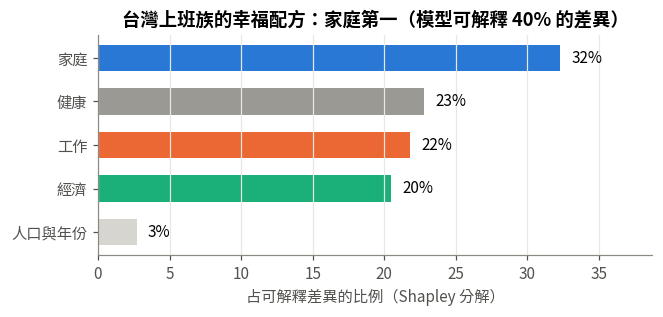

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
order = ["家庭", "健康", "工作", "經濟", "人口與年份"]
cols = [C_FAMILY, C_HEALTH, C_WORK, C_ECON, PALETTE["grey_light"]]
vals = (shap / shap.sum() * 100)[order]
ax.barh(order, vals, color=cols, height=0.6)
for i, v in enumerate(vals): ax.text(v + 0.8, i, f"{v:.0f}%", va="center", fontsize=10)
ax.invert_yaxis(); ax.set_xlim(0, max(vals) * 1.2); ax.set_xlabel("占可解釋差異的比例（Shapley 分解）"); ax.grid(axis="y", visible=False)
ax.set_title(f"台灣上班族的幸福配方：家庭第一（模型可解釋 {cache[frozenset(names)]*100:.0f}% 的差異）")
savefig(fig, "fig03_shapley_recipe")

## 3. 非線性：從「不太滿意」到「還算滿意」，和從「還算」到「很滿意」，一樣重要嗎？

In [6]:
F2 = "swb ~ C(jobsat, Treatment(3)) + C(famsat, Treatment(3)) + C(econsat, Treatment(3)) + health + age + I(age**2) + female + web + C(year)"
m2 = fit(F2, emp)
ct = coef_table(m2)
ct[ct.index.str.contains("sat")]

,coef,se,p,ci_low,ci_high
"C(jobsat, Treatment(3))[T.1.0]",-14.0190,1.4044,0.0,-16.7716,-11.2664
"C(jobsat, Treatment(3))[T.2.0]",-6.5018,0.4206,0.0,-7.3263,-5.6774
"C(jobsat, Treatment(3))[T.4.0]",5.0737,0.3894,0.0,4.3104,5.8370
"C(famsat, Treatment(3))[T.1.0]",-20.7355,1.6334,0.0,-23.9370,-17.5341
"C(famsat, Treatment(3))[T.2.0]",-9.1508,0.5666,0.0,-10.2612,-8.0403
"C(famsat, Treatment(3))[T.4.0]",7.4642,0.3270,0.0,6.8232,8.1051
"C(econsat, Treatment(3))[T.1.0]",-10.5284,0.6452,0.0,-11.7930,-9.2638
"C(econsat, Treatment(3))[T.2.0]",-3.8952,0.2922,0.0,-4.4680,-3.3225
"C(econsat, Treatment(3))[T.4.0]",3.0483,0.6225,0.0,1.8282,4.2684


PosixPath('figures/fig03b_nonlinear.png')

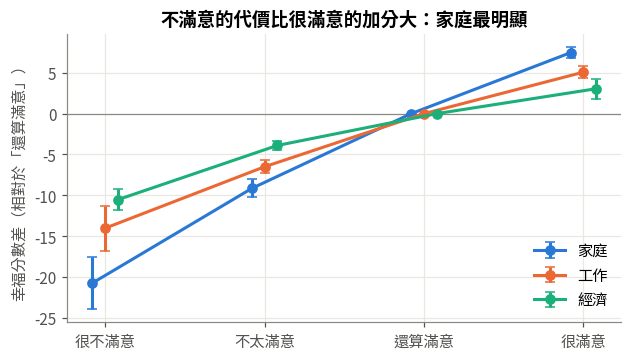

In [7]:
lab = {1: "很不滿意", 2: "不太滿意", 3: "還算滿意", 4: "很滿意"}
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for var, col, name in [("famsat", C_FAMILY, "家庭"), ("jobsat", C_WORK, "工作"), ("econsat", C_ECON, "經濟")]:
    xs, ys, lo, hi = [], [], [], []
    for k in [1, 2, 3, 4]:
        if k == 3:
            xs.append(k); ys.append(0); lo.append(0); hi.append(0); continue
        key = f"C({var}, Treatment(3))[T.{float(k)}]"
        xs.append(k); ys.append(m2.params[key]); ci = m2.conf_int().loc[key]; lo.append(ci[0]); hi.append(ci[1])
    ys, lo, hi = map(np.array, (ys, lo, hi))
    ax.errorbar(np.array(xs) + {"famsat": -0.08, "jobsat": 0, "econsat": 0.08}[var], ys, yerr=[ys - lo, hi - ys], marker="o", color=col, label=name, capsize=3)
ax.axhline(0, color="#8a8984", lw=0.8)
ax.set_xticks([1, 2, 3, 4], [lab[k] for k in [1, 2, 3, 4]]); ax.set_ylabel("幸福分數差（相對於「還算滿意」）")
ax.legend(); ax.set_title("不滿意的代價比很滿意的加分大：家庭最明顯")
savefig(fig, "fig03b_nonlinear")

## 4. 「木桶理論」：幸福取決於最差的那個領域嗎？

加法模型假設工作與家庭可以互相彌補（家庭好可以抵消工作差）。如果幸福其實由最弱的一塊板決定（非補償型），那麼「min(工作, 家庭)」應該帶來額外的解釋力。

In [8]:
for c in ["jobsat", "famsat"]: emp[c + "_z"] = z(emp[c])
emp["min_jf"] = emp[["jobsat_z", "famsat_z"]].min(axis=1)
emp["jf_inter"] = emp.jobsat_z * emp.famsat_z
base = "swb ~ jobsat_z + famsat_z + econsat + health + age + I(age**2) + female + web + C(year)"
mb = fit(base, emp); mm = fit(base + " + min_jf", emp); mi = fit(base + " + jf_inter", emp)
print("加法模型 R² =", round(mb.rsquared, 4))
print("加上 min(工作,家庭)：R² =", round(mm.rsquared, 4), " min 係數 =", round(mm.params["min_jf"], 2), " p =", round(mm.pvalues["min_jf"], 4))
print("加上 工作×家庭 交互作用：R² =", round(mi.rsquared, 4), " 係數 =", round(mi.params["jf_inter"], 2), " p =", round(mi.pvalues["jf_inter"], 4))
print("交叉驗證 R²：加法", round(cv_r2(mb.model.exog, mb.model.endog)[0], 4), " ＋min", round(cv_r2(mm.model.exog, mm.model.endog)[0], 4))

加法模型 R² = 0.3976
加上 min(工作,家庭)：R² = 0.4  min 係數 = 2.03  p = 0.0
加上 工作×家庭 交互作用：R² = 0.3976  係數 = -0.07  p = 0.5126
交叉驗證 R²：加法 0.3962  ＋min 0.3983


## 5. 全體樣本（含沒有工作的人）：家庭、經濟、健康、有沒有工作

In [9]:
allr = main.dropna(subset=["swb", "famsat", "econsat", "health", "age", "female", "employed"]).copy()
mall = fit("swb ~ famsat + econsat + health + employed + age + I(age**2) + female + web + C(year)", allr)
print("N =", len(allr))
coef_table(mall, ["famsat", "econsat", "health", "employed"])

N = 16346


,coef,se,p,ci_low,ci_high
famsat,9.4102,0.2484,0.0000,8.9233,9.8970
econsat,6.2489,0.2080,0.0000,5.8413,6.6565
health,5.9137,0.1702,0.0000,5.5801,6.2472
employed,-0.0556,0.4076,0.8915,-0.8544,0.7432


## 6. 18 年趨勢：權重有沒有變？（RR2007–RR2024，兩題版幸福分數，有工作者）

In [10]:
L = long[(long.employed == 1)].dropna(subset=["swb2", "jobsat", "famsat", "health", "age"]).copy()
rows = []
for y, g in L.groupby("year"):
    g = g.copy()
    for c in ["swb2", "jobsat", "famsat", "health"]: g[c] = z(g[c])
    m = smf.ols("swb2 ~ jobsat + famsat + health + age + I(age**2) + female", g).fit(cov_type="HC1")
    for v, name in [("jobsat", "工作"), ("famsat", "家庭"), ("health", "健康")]:
        rows.append(dict(year=y, 領域=name, beta=m.params[v], lo=m.conf_int().loc[v, 0], hi=m.conf_int().loc[v, 1], N=len(g)))
trend = pd.DataFrame(rows)
trend.pivot(index="year", columns="領域", values="beta").round(3)

領域,健康,家庭,工作
year,,,
2007,0.253,0.251,0.224
2008,0.243,0.227,0.219
2009,0.230,0.267,0.238
2010,0.246,0.248,0.254
2011,0.253,0.267,0.198
2012,0.242,0.278,0.202
2014,0.262,0.255,0.203
2016,0.246,0.283,0.238
2018,0.245,0.294,0.232


PosixPath('figures/fig03c_weight_trend.png')

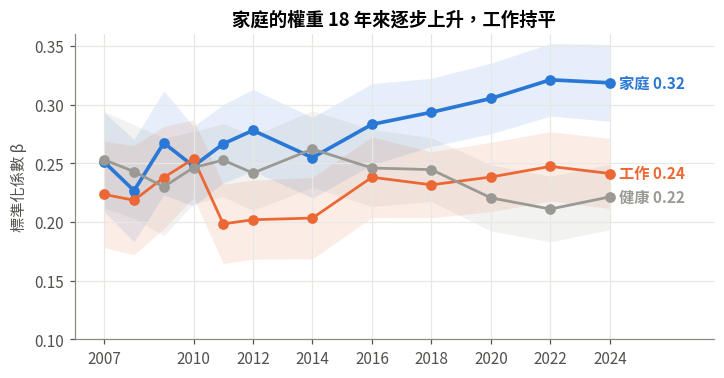

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for name, col in [("家庭", C_FAMILY), ("工作", C_WORK), ("健康", C_HEALTH)]:
    t = trend[trend.領域 == name]
    ax.fill_between(t.year, t.lo, t.hi, color=col, alpha=0.12, lw=0)
    ax.plot(t.year, t.beta, marker="o", color=col, label=name, lw=2.4 if name == "家庭" else 1.8)
    ax.annotate(f"{name} {t.beta.iloc[-1]:.2f}", (t.year.iloc[-1], t.beta.iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", color=col, fontsize=10, fontweight="bold")
ax.set_xlim(2006, 2027.5); ax.set_ylabel("標準化係數 β"); ax.set_ylim(0.1, 0.36)
ax.set_xticks([2007, 2010, 2012, 2014, 2016, 2018, 2020, 2022, 2024])
ax.set_title("家庭的權重 18 年來逐步上升，工作持平")
savefig(fig, "fig03c_weight_trend")

### 6.1 這個上升是真的變化，還是樣本變老（組成效果）？

PSFD 是追蹤調查，同一群人每年都老一歲；2009、2016 又補進年輕世代。如果「年紀越大越看重家庭」（社會情緒選擇理論，Carstensen, 1999：人越感到時間有限，越重視親密關係），平均權重的上升可能只是樣本年齡結構改變。
檢定方法：合併 12 波，讓家庭與工作的效果隨「年份」與「年齡」同時變化，看控制年齡交互作用後，年份趨勢是否還在。

In [12]:
Lz = L.copy()
for c in ["swb2", "jobsat", "famsat", "health"]: Lz[c] = Lz.groupby("year")[c].transform(z)
Lz["t"] = (Lz.year - 2016) / 10       # 每 10 年
Lz["a"] = (Lz.age - 45) / 10          # 每 10 歲
Lz["coh"] = (Lz.birth_year - 1960) / 10
specs = {
    "只有年份趨勢": "swb2 ~ (jobsat + famsat) * t + health + age + I(age**2) + female",
    "＋年齡交互作用": "swb2 ~ (jobsat + famsat) * (t + a) + health + age + I(age**2) + female",
    "＋年齡＋網路自填": "swb2 ~ (jobsat + famsat) * (t + a) + health + age + I(age**2) + female + web",
}
rows = []
for k, f in specs.items():
    m = fit(f, Lz)
    for v in ["famsat:t", "jobsat:t", "famsat:a", "jobsat:a"]:
        if v in m.params: rows.append(dict(模型=k, 項=v, coef=m.params[v], p=m.pvalues[v]))
pd.DataFrame(rows).pivot(index="項", columns="模型", values="coef").round(3)

模型,只有年份趨勢,＋年齡交互作用,＋年齡＋網路自填
項,,,
famsat:a,NaN,0.027,0.026
famsat:t,0.045,0.046,0.052
jobsat:a,NaN,-0.009,-0.009
jobsat:t,0.012,0.014,0.020


In [13]:
pd.DataFrame(rows).pivot(index="項", columns="模型", values="p").round(4)

模型,只有年份趨勢,＋年齡交互作用,＋年齡＋網路自填
項,,,
famsat:a,NaN,0.0000,0.0000
famsat:t,0.0000,0.0000,0.0000
jobsat:a,NaN,0.1139,0.0856
jobsat:t,0.2349,0.1728,0.0513


### 6.2 同一批人追 18 年：1953–1963 年出生的主樣本（1999 年首波）

In [14]:
rows = []
co = L[(L.birth_year.between(1953, 1963))]
for y, g in co.groupby("year"):
    g = g.copy()
    for c in ["swb2", "jobsat", "famsat", "health"]: g[c] = z(g[c])
    m = smf.ols("swb2 ~ jobsat + famsat + health + female", g).fit(cov_type="HC1")
    rows.append(dict(year=y, N=len(g), 平均年齡=g.age.mean(), 家庭=m.params["famsat"], 工作=m.params["jobsat"]))
coh_tab = pd.DataFrame(rows).round(3)
coh_tab

,year,N,平均年齡,家庭,工作
0,2007,626,49.674,0.230,0.190
1,2008,603,50.697,0.223,0.238
2,2009,528,51.485,0.267,0.248
3,2010,483,52.522,0.198,0.180
4,2011,473,53.467,0.312,0.128
5,2012,472,54.422,0.366,0.175
6,2014,413,56.334,0.198,0.229
7,2016,354,58.212,0.255,0.183
8,2018,326,60.255,0.325,0.122
9,2020,264,61.917,0.385,0.161


### 6.3 同一年份、不同年齡層：年紀越大越看重家庭嗎？

In [15]:
Lz["age_g"] = pd.cut(Lz.age, [0, 39, 49, 59, 120], labels=["<40", "40–49", "50–59", "60+"])
rows = []
for (p, ag), g in Lz.assign(period=np.where(Lz.year <= 2012, "2007–2012", np.where(Lz.year <= 2018, "2014–2018", "2020–2024"))).groupby(["period", "age_g"], observed=True):
    m = smf.ols("swb2 ~ jobsat + famsat + health + female", g).fit()
    rows.append(dict(期間=p, 年齡=ag, N=len(g), 家庭=m.params["famsat"], 工作=m.params["jobsat"]))
age_period = pd.DataFrame(rows)
age_period.pivot(index="年齡", columns="期間", values="家庭").round(3)

期間,2007–2012,2014–2018,2020–2024
年齡,,,
40–49,0.271,0.291,0.318
50–59,0.279,0.245,0.353
60+,0.340,0.335,0.408
<40,0.241,0.275,0.300


In [16]:
age_period.pivot(index="年齡", columns="期間", values="工作").round(3)

期間,2007–2012,2014–2018,2020–2024
年齡,,,
40–49,0.268,0.191,0.250
50–59,0.181,0.217,0.292
60+,0.161,0.220,0.184
<40,0.221,0.230,0.239


### 6.4 上升的是「斜率」還是「變異」？已婚與未婚都在上升嗎？

標準化係數 β = 原始斜率 × (滿意度標準差 ÷ 幸福標準差)。如果只是家庭滿意度的分散程度變大，β 也會上升。所以同時看原始斜率（每高一級滿意度，幸福分數多幾分）與標準差。
另外，台灣結婚與生育越來越少（2025 年出生數 10.8 萬、結婚 10.4 萬對，皆為新低），若家庭權重上升只發生在已婚者，可能反映「選擇進入家庭的人更在乎家庭」。

In [17]:
rows = []
for y, g in L.groupby("year"):
    m = smf.ols("swb2 ~ jobsat + famsat + health + age + I(age**2) + female", g).fit()
    rows.append(dict(year=y, 家庭原始斜率=m.params["famsat"], 工作原始斜率=m.params["jobsat"], 家庭滿意SD=g.famsat.std(), 工作滿意SD=g.jobsat.std(), 幸福SD=g.swb2.std()))
raw_tr = pd.DataFrame(rows).round(3)
raw_tr

,year,家庭原始斜率,工作原始斜率,家庭滿意SD,工作滿意SD,幸福SD
0,2007,9.141,7.501,0.582,0.631,21.185
1,2008,8.262,7.585,0.583,0.612,21.235
2,2009,9.890,8.710,0.594,0.600,21.953
3,2010,8.880,8.583,0.563,0.598,20.206
4,2011,9.342,6.508,0.550,0.587,19.254
5,2012,9.340,6.305,0.574,0.617,19.260
6,2014,8.874,6.906,0.547,0.561,19.061
7,2016,9.582,8.115,0.554,0.550,18.729
8,2018,9.576,7.555,0.570,0.570,18.599
9,2020,10.528,8.320,0.597,0.590,20.601


In [18]:
Lm = Lz[Lz.year >= 2016].copy()
Lm = Lm.merge(long[["pid", "year", "married"]].rename(columns={"married": "mar_now"}), on=["pid", "year"], how="left")
rows = []
for (y, mg), g in Lm.dropna(subset=["mar_now"]).groupby(["year", "mar_now"]):
    m = smf.ols("swb2 ~ jobsat + famsat + health + age + female", g).fit()
    rows.append(dict(year=y, 群體="已婚" if mg == 1 else "未婚/其他", 家庭=m.params["famsat"], 工作=m.params["jobsat"], N=len(g)))
pd.DataFrame(rows).pivot(index="year", columns="群體", values="家庭").round(3)

群體,已婚,未婚/其他
year,,
2016,0.296,0.252
2018,0.317,0.267
2020,0.326,0.272
2022,0.351,0.276
2024,0.291,0.329


## 7. 不同群體的配方一樣嗎？（2020–2024 有工作者）

In [19]:
emp["age_g"] = pd.cut(emp.age, [0, 39, 49, 59, 120], labels=["<40", "40–49", "50–59", "60+"])
def cat(conds, labels):
    return pd.Series(np.select(conds, labels, default=None), index=emp.index)
emp["edu_g"] = cat([emp.edu_years >= 16, emp.edu_years < 16], ["大學以上", "專科以下"])
emp["inc_g"] = pd.qcut(emp.income, 3, labels=["收入低", "收入中", "收入高"])
emp["sex_g"] = cat([emp.female == 1, emp.female == 0], ["女性", "男性"])
emp["mar_g"] = cat([emp.married == 1, emp.married == 0], ["已婚", "未婚/離婚/喪偶"])
emp["kid_g"] = cat([emp.kid_under6 == 1, emp.has_kids == 1, emp.has_kids == 0], ["有 6 歲以下子女", "子女都 6 歲以上", "沒有子女"])
emp["type_g"] = cat([emp.respondent_type == 3, emp.respondent_type == 1], ["子女轉主樣本（較年輕）", "原始主樣本"])
ezz = emp.copy()
for c in ["swb", "jobsat", "famsat", "econsat", "health"]: ezz[c] = z(ezz[c])
rows = []
for col in ["sex_g", "age_g", "mar_g", "kid_g", "edu_g", "inc_g", "type_g"]:
    for lv, g in ezz.groupby(col, observed=True):
        if len(g) < 200: continue
        m = fit("swb ~ jobsat + famsat + econsat + health + age + female + web + C(year)", g)
        for v, nm in [("famsat", "家庭"), ("jobsat", "工作")]:
            ci = m.conf_int().loc[v]
            rows.append(dict(分組=col, 群體=str(lv), 領域=nm, beta=m.params[v], lo=ci[0], hi=ci[1], N=len(g)))
sub = pd.DataFrame(rows)
sub.pivot_table(index=["分組", "群體", "N"], columns="領域", values="beta").round(3)

領域                          家庭     工作
分組     群體          N                 
age_g  40–49       4806  0.289  0.205
       50–59       764   0.294  0.204
       60+         819   0.360  0.149
       <40         6690  0.279  0.202
edu_g  大學以上        8421  0.280  0.215
       專科以下        4217  0.295  0.180
inc_g  收入中         3971  0.273  0.239
       收入低         4211  0.301  0.155
       收入高         3811  0.292  0.210
kid_g  子女都 6 歲以上   4675  0.317  0.167
       有 6 歲以下子女   2364  0.330  0.162
       沒有子女        6040  0.248  0.228
mar_g  已婚          7240  0.298  0.180
       未婚/離婚/喪偶    5806  0.265  0.217
sex_g  女性          5677  0.305  0.194
       男性          7402  0.272  0.204
type_g 原始主樣本       8987  0.293  0.197
       子女轉主樣本（較年輕） 4092  0.275  0.202

PosixPath('figures/fig03d_subgroups.png')

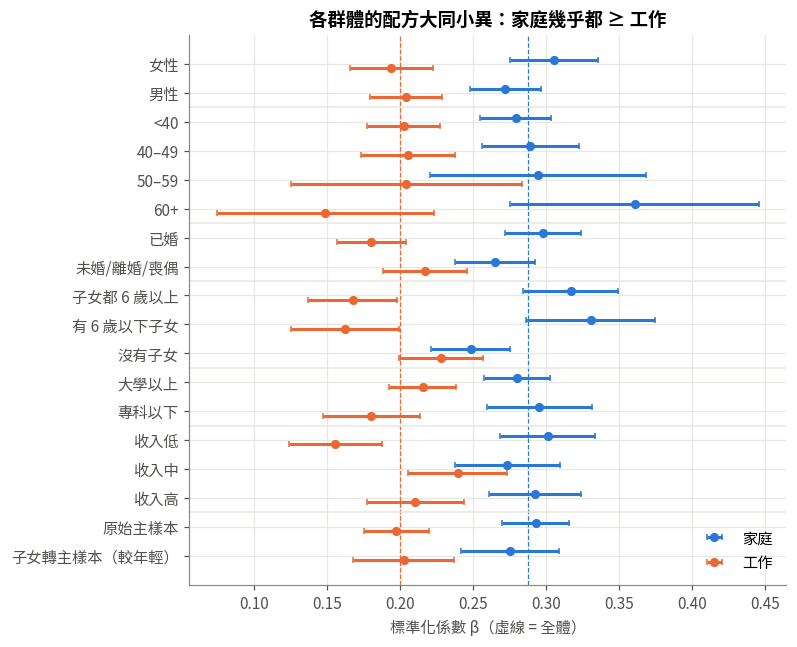

In [20]:
labels_ = sub[sub.領域 == "家庭"][["分組", "群體"]].apply(lambda r: r.群體, axis=1).tolist()
fig, ax = plt.subplots(figsize=(7, 6.5))
yy = np.arange(len(labels_))
for nm, col, off in [("家庭", C_FAMILY, -0.15), ("工作", C_WORK, 0.15)]:
    t = sub[sub.領域 == nm]
    ax.errorbar(t.beta, yy + off, xerr=[t.beta - t.lo, t.hi - t.beta], fmt="o", color=col, label=nm, capsize=2, ms=5)
ax.set_yticks(yy, labels_); ax.invert_yaxis()
ax.axvline(beta.loc["famsat", "coef"], color=C_FAMILY, ls="--", lw=0.8)
ax.axvline(beta.loc["jobsat", "coef"], color=C_WORK, ls="--", lw=0.8)
prev = None
for i, g in enumerate(sub[sub.領域 == "家庭"].分組):
    if prev is not None and g != prev: ax.axhline(i - 0.5, color="#e8e7e3", lw=1)
    prev = g
ax.set_xlabel("標準化係數 β（虛線 = 全體）"); ax.legend(loc="lower right")
ax.set_title("各群體的配方大同小異：家庭幾乎都 ≥ 工作")
savefig(fig, "fig03d_subgroups")

In [21]:
trend.to_csv(DERIVED / "weights_trend_2007_2024.csv", index=False)
sub.to_csv(DERIVED / "weights_subgroups.csv", index=False)
pd.DataFrame({"shapley": shap}).to_csv(DERIVED / "shapley_recipe.csv")